In [1]:
# import libraries
import pandas as pd
import seaborn as sns

import matplotlib 
import matplotlib.pyplot as plt
plt.style.use('default') # 'ggplot'
from matplotlib.pyplot import figure

matplotlib.rcParams['figure.figsize'] = (6,4) # adjusts the config of the plots 


# Import and Assess Data sets

In [2]:
pd.set_option('display.max_rows', None)

## Assess borrower profile data

In [3]:
## import file 1
profileData = pd.read_csv('data/borrower_profiles.csv')
profileData.head()

,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt
0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892
1,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,2,869
2,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806
3,BRW-0004,43,TX,High School,Full-Time,19,35036,701,Mortgage,2,928
4,BRW-0005,46,NY,High School,Full-Time,18,44528,715,Own,0,608


In [4]:
# assess data types and null values
profileData.info(verbose = True, memory_usage = 'deep', show_counts = True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   borrower_id            500 non-null    object
 1   age                    500 non-null    int64 
 2   state                  500 non-null    object
 3   education_level        500 non-null    object
 4   employment_status      500 non-null    object
 5   years_employed         500 non-null    int64 
 6   annual_income          500 non-null    int64 
 7   credit_score           500 non-null    int64 
 8   home_ownership         500 non-null    object
 9   dependents             500 non-null    int64 
 10  existing_monthly_debt  500 non-null    int64 
dtypes: int64(6), object(5)
memory usage: 159.4 KB


In [5]:
# assess overall range of values
profileData.describe()

,age,years_employed,annual_income,credit_score,dependents,existing_monthly_debt
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,44.986000,10.854000,64471.484000,704.952000,1.356000,1585.166000
std,13.539736,9.301706,28959.837645,97.339157,1.252358,1089.979915
min,22.000000,0.000000,12549.000000,528.000000,0.000000,124.000000
25%,33.000000,3.000000,42968.250000,617.750000,0.000000,788.750000
50%,45.000000,8.000000,59282.500000,708.000000,1.000000,1312.000000
75%,57.000000,17.000000,79780.500000,794.250000,2.000000,2131.750000
max,68.000000,35.000000,157047.000000,850.000000,4.000000,6130.000000


In [6]:
# assess # of unique values per column
profileData.nunique()

borrower_id              500
age                       47
state                     30
education_level            5
employment_status          5
years_employed            36
annual_income            499
credit_score             251
home_ownership             3
dependents                 5
existing_monthly_debt    461
dtype: int64

In [7]:
# review samples of unique values per column
profileData.apply(pd.unique)

borrower_id              [BRW-0001, BRW-0002, BRW-0003, BRW-0004, BRW-0...
age                      [62, 24, 50, 43, 46, 40, 35, 30, 39, 54, 32, 4...
state                    [CT, CO, NC, TX, NY, OR, GA, KY, UT, WA, FL, A...
education_level          [High School, Bachelor, Doctorate, Master, Ass...
employment_status        [Self-Employed, Full-Time, Contract, Part-Time...
years_employed           [6, 4, 22, 19, 18, 8, 5, 14, 15, 2, 0, 9, 28, ...
annual_income            [31020, 40188, 41014, 35036, 44528, 157047, 84...
credit_score             [596, 543, 611, 701, 715, 749, 576, 563, 643, ...
home_ownership                                       [Rent, Own, Mortgage]
dependents                                                 [1, 2, 0, 3, 4]
existing_monthly_debt    [892, 869, 1806, 928, 608, 3076, 1682, 939, 64...
dtype: object

### Review age data

##### Notes
##### * Ages range from 22-68, mean of 45
##### * Data is fairly evenly distributed
##### * Interesting - There are 40 borrowers under 65 that are retired
##### * Create groups to work with data further

In [8]:
profileData.age.describe()

count    500.000000
mean      44.986000
std       13.539736
min       22.000000
25%       33.000000
50%       45.000000
75%       57.000000
max       68.000000
Name: age, dtype: float64

<Axes: ylabel='age'>

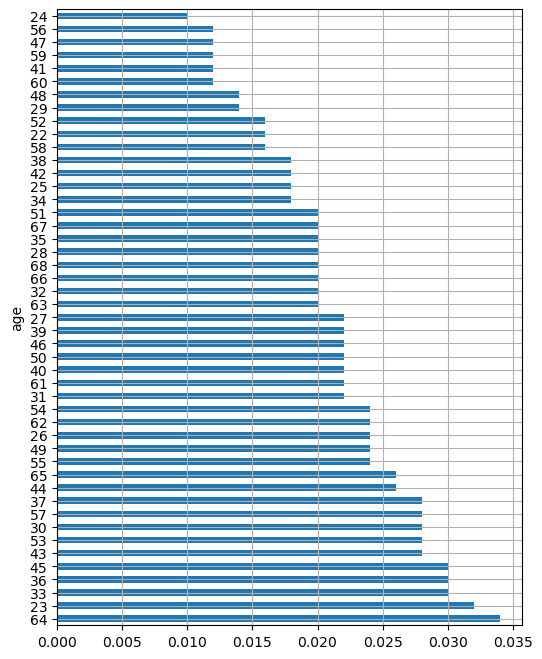

In [9]:
# assess proportion by data value
matplotlib.rcParams['figure.figsize'] = (6,8) # adjusts the config of the plots 
profileData.age.value_counts(normalize = True).plot.barh(grid = True)
# proportion range from 0.01-0.03
# largest group is 64


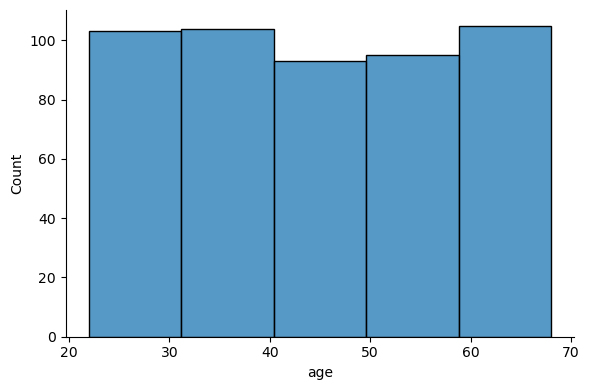

In [10]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = profileData,
                x = 'age', # fairly even distribution
                bins = 5, height = 4, aspect = 1.5)

# Note -- 40's are the smallest group, but they contain the mean age

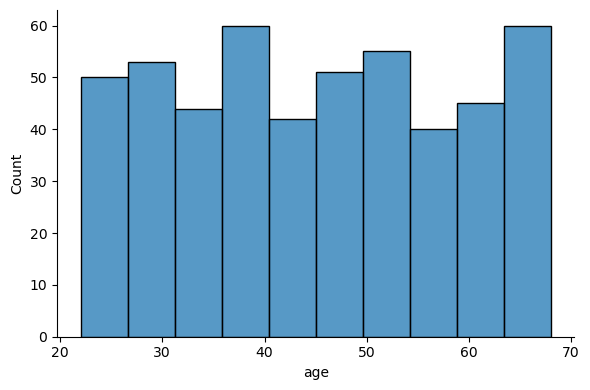

In [11]:
# Assess data distribution - smaller groups
g = sns.displot(kind = 'hist', data = profileData,
                x = 'age', # fairly even distribution
                bins = 10, height = 4, aspect = 1.5)

# Note -- each decade has skewed segments, except 20s

### Review state data

##### Notes
##### * 30/50 states represented. Assumed data represents all states that Horizon does business in (none are missing).
##### Questions for later
##### * Does state relate to default rate?

<Axes: ylabel='state'>

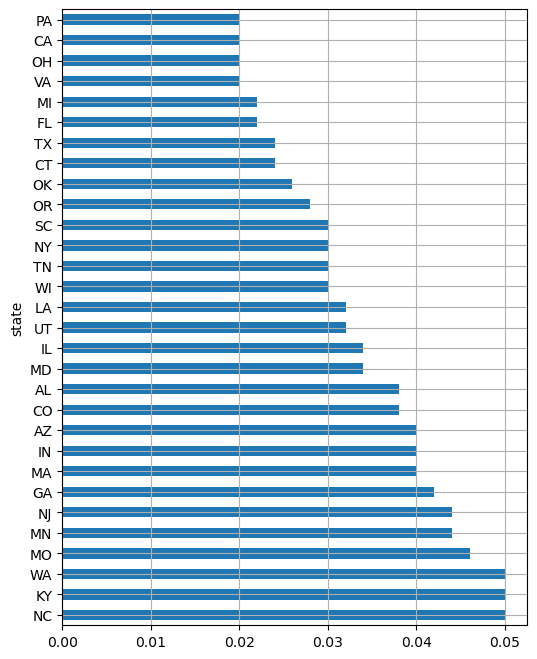

In [12]:
# Assess value proportions
matplotlib.rcParams['figure.figsize'] = (6,8) # adj plot size
profileData.state.value_counts(normalize = True).plot.barh(grid = True)
# fairly even - 2-5%

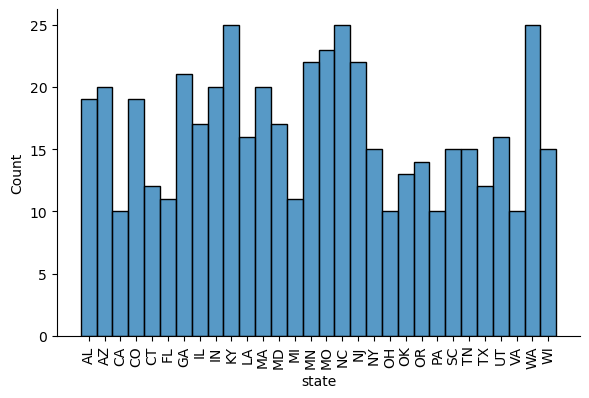

In [13]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = profileData.sort_values(by = 'state', ascending = True),
                x = 'state', # surprisingly 800+ is biggest cat!
                bins = 10, height = 4, aspect = 1.5)

for ax in g.axes.flat:
    ax.tick_params('x', labelrotation = 90)


### Review education level data
##### Notes
##### * Skewed heavy on Bachelors, and low on Doctorates

<Axes: xlabel='education_level'>

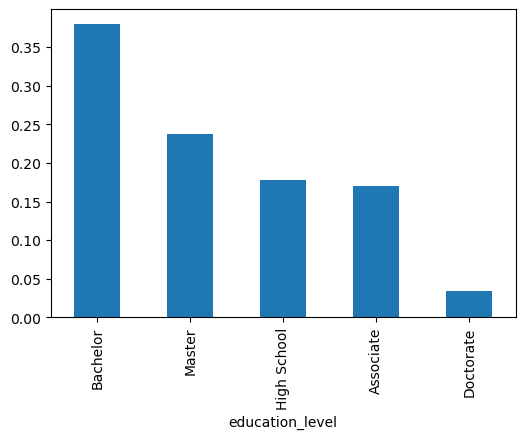

In [14]:
matplotlib.rcParams['figure.figsize'] = (6,4) # adj plot size
profileData.education_level.value_counts(normalize = True).plot.bar()
# slightly skewed - Bachelor has the most, with fairly even proportions on Master, HS and Assoc. Doctorates LOW

### Review employment status data

In [15]:
# Assess proportion of values in data
profileData.employment_status.value_counts(normalize = True)
# half of data set are full time workers, evenly split amongst other cats

employment_status
Full-Time        0.504
Self-Employed    0.180
Part-Time        0.110
Contract         0.108
Retired          0.098
Name: proportion, dtype: float64

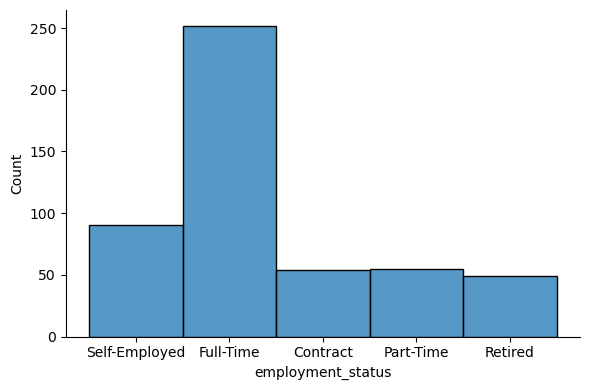

In [16]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = profileData,
                x = 'employment_status',
                bins = 10, height = 4, aspect = 1.5
               #, hue = 'age_bin'
               )

### Review Years Employed Data
##### Notes
##### Skewed toward on 0-5 years of employment (or lower #s of years)
##### Top 7 categories are 0-6 years
#####
##### Questions -- is lower # of years employed affecting current default rate?

In [17]:
# Assess proportion of values in data
profileData.years_employed.value_counts(normalize = True)
# majority of top 10 categories are under 10 years

years_employed
2     0.084
1     0.074
3     0.064
0     0.064
5     0.050
4     0.050
6     0.046
14    0.040
7     0.040
8     0.038
11    0.034
9     0.032
17    0.030
18    0.028
13    0.026
10    0.026
16    0.026
12    0.024
20    0.022
15    0.022
24    0.018
22    0.018
30    0.016
27    0.016
19    0.016
25    0.014
28    0.012
34    0.012
33    0.010
21    0.010
29    0.008
32    0.008
31    0.008
26    0.006
35    0.004
23    0.004
Name: proportion, dtype: float64

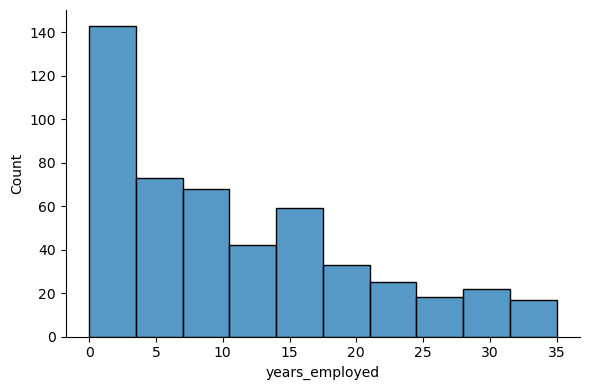

In [18]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = profileData,
                x = 'years_employed',
                bins = 10, height = 4, aspect = 1.5)

### Review Annual Income Data
##### NOTES
##### slight left skew with right tail

In [19]:
# Assess proportion of values in data
profileData.annual_income.value_counts(normalize = True)

annual_income
28195     0.004
31020     0.002
101319    0.002
58731     0.002
117172    0.002
72256     0.002
52919     0.002
105131    0.002
109449    0.002
137015    0.002
62522     0.002
43022     0.002
55754     0.002
94525     0.002
135142    0.002
70784     0.002
53539     0.002
88548     0.002
17078     0.002
57129     0.002
65650     0.002
44951     0.002
50342     0.002
51267     0.002
57272     0.002
74791     0.002
32850     0.002
27000     0.002
69849     0.002
29277     0.002
71191     0.002
73366     0.002
42400     0.002
29087     0.002
51445     0.002
55596     0.002
49527     0.002
49297     0.002
32803     0.002
93191     0.002
43512     0.002
90383     0.002
36926     0.002
43058     0.002
52736     0.002
71139     0.002
125043    0.002
117130    0.002
78653     0.002
96677     0.002
55827     0.002
90781     0.002
132747    0.002
79686     0.002
77060     0.002
46283     0.002
74246     0.002
31671     0.002
57507     0.002
46787     0.002
41748     0.002
41212     

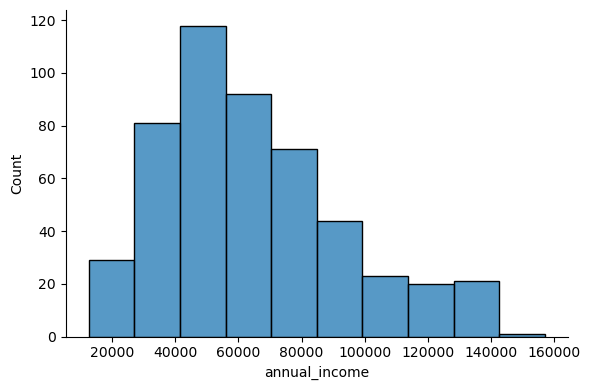

In [20]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = profileData,
                x = 'annual_income',
                bins = 10, height = 4, aspect = 1.5)

### Review Credit Score Data
##### NOTES
##### * highest category has largest proportion of borrowers --- makes sense if you're using credit score to approve loans -- those with higher should be more represented. However, counts don't really increase as credit score increases, except for highest cat (850).

In [21]:
# proportions of values in data set
profileData.credit_score.value_counts(normalize = True) 
# largest cat is 850 @ 6%. 674 & 582 have 1%, and everything else is less than 1%

credit_score
850    0.060
674    0.010
582    0.010
709    0.008
796    0.008
568    0.008
661    0.008
811    0.008
622    0.008
711    0.008
704    0.008
846    0.008
619    0.008
615    0.008
809    0.008
663    0.008
576    0.008
554    0.008
725    0.008
823    0.006
840    0.006
648    0.006
585    0.006
772    0.006
593    0.006
686    0.006
697    0.006
716    0.006
794    0.006
845    0.006
610    0.006
583    0.006
820    0.006
543    0.006
842    0.006
829    0.006
635    0.006
818    0.006
849    0.006
750    0.006
555    0.006
754    0.006
761    0.006
730    0.006
611    0.006
715    0.006
801    0.006
736    0.006
783    0.006
813    0.006
609    0.006
570    0.006
698    0.006
700    0.006
550    0.006
714    0.006
721    0.006
641    0.006
672    0.006
625    0.006
827    0.004
693    0.004
836    0.004
551    0.004
764    0.004
778    0.004
748    0.004
578    0.004
742    0.004
574    0.004
819    0.004
743    0.004
828    0.004
621    0.004
762    0.004
605    0.004

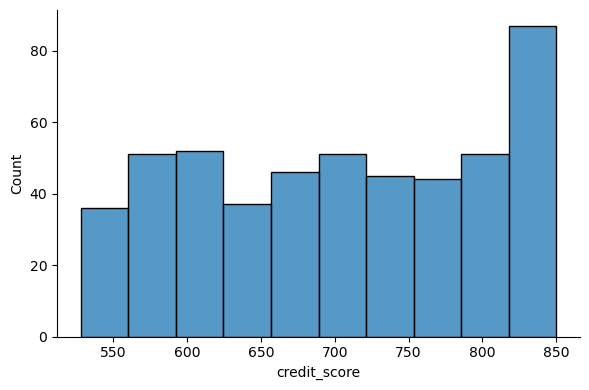

In [22]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = profileData,
                x = 'credit_score',
                bins = 10, height = 4, aspect = 1.5)

### Review home ownership data

In [23]:
# proportions of values in data set
profileData.home_ownership.value_counts(normalize = True) 
# Groups all have a fair count

home_ownership
Mortgage    0.432
Rent        0.354
Own         0.214
Name: proportion, dtype: float64

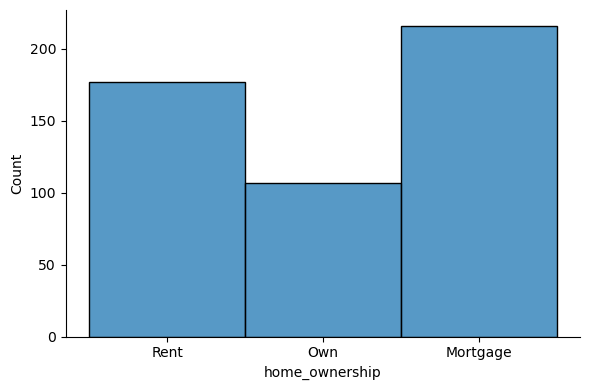

In [24]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = profileData,
                x = 'home_ownership',
                bins = 10, height = 4, aspect = 1.5)

### Review Dependents Data

In [25]:
profileData.dependents.value_counts(normalize = True) 
# left skew with right tail

dependents
0    0.344
2    0.226
1    0.222
3    0.150
4    0.058
Name: proportion, dtype: float64

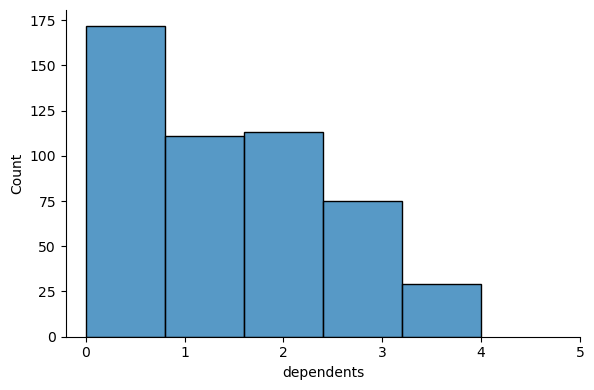

In [26]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = profileData,
                x = 'dependents',
                bins = 5, height = 4, aspect = 1.5)
for ax in g.axes.flat:
    ax.set(xticks = [x for x in range(0, 6, 1)])

## Assess Application Data File

In [27]:
# import file 2
appData = pd.read_csv('data/loan_applications.csv')
appData.head()

,loan_id,borrower_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted
0,LN-00001,BRW-0001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0
1,LN-00002,BRW-0001,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1
2,LN-00003,BRW-0002,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0
3,LN-00004,BRW-0003,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,34,1
4,LN-00005,BRW-0004,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,0,0


In [28]:
appData.info(verbose = True, memory_usage = 'deep', show_counts = True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   loan_id           601 non-null    object 
 1   borrower_id       601 non-null    object 
 2   application_date  601 non-null    object 
 3   loan_purpose      601 non-null    object 
 4   loan_amount       601 non-null    float64
 5   term_months       601 non-null    int64  
 6   interest_rate     601 non-null    float64
 7   monthly_payment   601 non-null    float64
 8   dti_ratio         601 non-null    float64
 9   loan_status       601 non-null    object 
 10  days_delinquent   601 non-null    int64  
 11  defaulted         601 non-null    int64  
dtypes: float64(4), int64(3), object(5)
memory usage: 202.9 KB


### Notes
Conversions needed:  
application date to datetime.  

Other:  
  Interest and dti ratio are expressed as percentages  
  defaulted is binary  
  no null values

In [29]:
appData.describe().T

,count,mean,std,min,25%,50%,75%,max
loan_amount,601.0,22148.252912,13215.261422,2000.00,10900.00,20400.00,32700.00,49800.00
term_months,601.0,36.539101,16.898192,12.00,24.00,36.00,48.00,60.00
interest_rate,601.0,10.641331,2.251153,5.86,8.94,10.54,12.33,15.86
monthly_payment,601.0,948.337654,864.959543,44.14,359.86,684.87,1165.20,4262.69
dti_ratio,601.0,49.680699,24.113652,7.60,32.20,48.10,62.40,177.40
days_delinquent,601.0,27.036606,47.802845,0.00,0.00,0.00,30.00,180.00
defaulted,601.0,0.242928,0.429209,0.00,0.00,0.00,0.00,1.00


In [30]:
# assess app date values to determine why they are classified as objects vs dates... 
appData.application_date.value_counts()

application_date
2024-06-01    6
2025-02-27    6
2025-05-18    5
2024-04-05    4
2025-01-19    4
2025-04-19    4
2024-11-18    4
2024-04-18    4
2024-06-13    4
2024-06-15    4
2024-06-28    4
2024-02-24    4
2024-06-23    4
2024-04-07    4
2024-07-25    4
2025-05-25    3
2024-04-11    3
2025-05-27    3
2024-12-21    3
2025-04-25    3
2024-09-30    3
2024-06-10    3
2025-01-25    3
2024-07-14    3
2024-10-08    3
2024-11-15    3
2024-05-09    3
2024-05-10    3
2024-11-07    3
2025-05-09    3
2024-01-05    3
2025-06-19    3
2024-11-09    3
2024-07-31    3
2024-01-06    3
2024-11-29    3
2024-08-29    3
2024-05-20    3
2024-04-15    3
2025-02-06    3
2024-03-09    3
2024-04-23    3
2025-06-28    3
2025-03-13    3
2024-06-22    3
2024-07-13    3
2024-06-20    3
2024-01-10    3
2025-01-18    3
2024-05-07    3
2024-06-05    2
2024-07-29    2
2025-05-26    2
2024-04-19    2
2025-02-21    2
2025-01-29    2
2025-06-07    2
2024-01-14    2
2024-04-08    2
2024-01-19    2
2024-04-22    2
2024-05

In [31]:
# convert application date to date time
appData[['application_date']] = appData[['application_date']].apply(pd.to_datetime)

In [32]:
appData.head()
appData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   loan_id           601 non-null    object        
 1   borrower_id       601 non-null    object        
 2   application_date  601 non-null    datetime64[ns]
 3   loan_purpose      601 non-null    object        
 4   loan_amount       601 non-null    float64       
 5   term_months       601 non-null    int64         
 6   interest_rate     601 non-null    float64       
 7   monthly_payment   601 non-null    float64       
 8   dti_ratio         601 non-null    float64       
 9   loan_status       601 non-null    object        
 10  days_delinquent   601 non-null    int64         
 11  defaulted         601 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(3), object(4)
memory usage: 56.5+ KB


In [33]:
appData.nunique()

loan_id             601
borrower_id         500
application_date    369
loan_purpose         10
loan_amount         341
term_months           5
interest_rate       426
monthly_payment     600
dti_ratio           413
loan_status           4
days_delinquent      94
defaulted             2
dtype: int64

In [34]:
appData.apply(pd.unique)

loan_id             [LN-00001, LN-00002, LN-00003, LN-00004, LN-00...
borrower_id         [BRW-0001, BRW-0002, BRW-0003, BRW-0004, BRW-0...
application_date    [2024-01-08T00:00:00.000000000, 2024-08-13T00:...
loan_purpose        [Vacation, Major Purchase, Moving, Auto Loan, ...
loan_amount         [16100.0, 5600.0, 44700.0, 9200.0, 11200.0, 28...
term_months                                      [36, 48, 12, 60, 24]
interest_rate       [13.05, 14.21, 12.37, 11.18, 9.66, 13.07, 10.2...
monthly_payment     [542.86, 153.62, 1492.59, 238.58, 359.61, 768....
dti_ratio           [55.5, 40.4, 70.5, 59.8, 44.1, 37.1, 49.9, 38....
loan_status                        [Paid Off, Default, Current, Late]
days_delinquent     [0, 138, 34, 38, 43, 105, 63, 15, 170, 168, 13...
defaulted                                                      [0, 1]
dtype: object

In [35]:
appData.isnull().sum()

loan_id             0
borrower_id         0
application_date    0
loan_purpose        0
loan_amount         0
term_months         0
interest_rate       0
monthly_payment     0
dti_ratio           0
loan_status         0
days_delinquent     0
defaulted           0
dtype: int64

In [36]:
appData.duplicated(keep = False).sum() # no duplicates

np.int64(0)

### Review Application Date Data
##### NOTES
##### Peak loans in May-July 2024. 
##### Lulls in loans between Sept-Nov 2024
##### No date range is under a count of 50

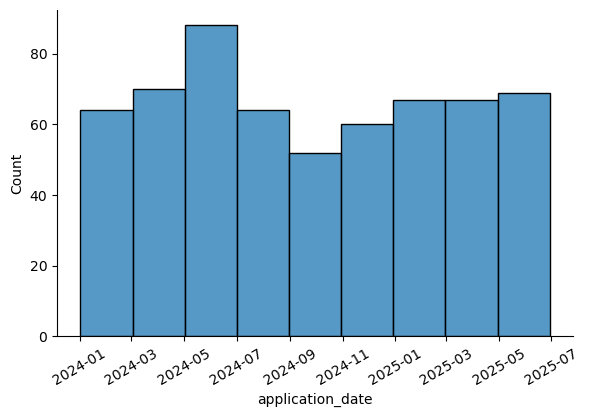

In [37]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                x = 'application_date',
                bins = 9, height = 4, aspect = 1.5)
for ax in g.axes.flat:
    ax.tick_params('x', labelrotation = 30)

### Review Loan Purpose Data
##### Data distributed 8-12% per category

In [38]:
appData.loan_purpose.value_counts(normalize = True) 

loan_purpose
Home Improvement      0.116473
Major Purchase        0.113145
Medical Expenses      0.113145
Vacation              0.103161
Auto Loan             0.098170
Business Loan         0.096506
Moving                0.093178
Wedding               0.093178
Education             0.088186
Debt Consolidation    0.084859
Name: proportion, dtype: float64

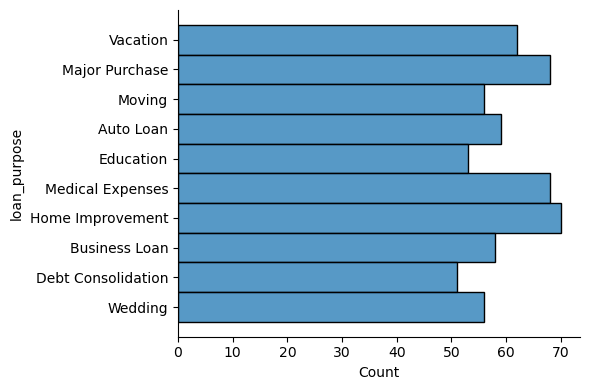

In [39]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                y = 'loan_purpose',
                bins = 10, height = 4, aspect = 1.5)

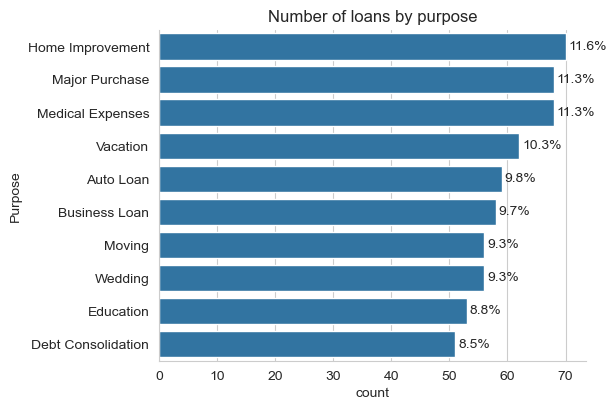

In [40]:
# Assess counts by purpose
sns.set_style('whitegrid')
g = sns.catplot(kind = 'count', data = appData,
                y = 'loan_purpose', 
                order = appData['loan_purpose'].value_counts().index,
                height = 4, aspect = 1.5)

total = len(appData)

for ax in g.axes.flat:
    ax.set(title = 'Number of loans by purpose', ylabel = 'Purpose' )

    for bar in ax.patches:
        pct = 100 * bar.get_width() / total

        ax.text(x = bar.get_width() + 0.5,
               y = bar.get_y() + bar.get_height() / 2,
               s = f'{pct:.1f}%',
               va = 'center')

g.savefig('images/purpose_counts.png')

### Review Loan Amount Data
##### About half of these loans are for less than $20k

In [62]:
appData.loan_amount.sum()

np.float64(13311100.0)

In [41]:
appData.loan_amount.value_counts(normalize = True) 

loan_amount
8800.0     0.009983
27200.0    0.008319
7000.0     0.008319
39200.0    0.008319
12900.0    0.008319
12800.0    0.006656
46500.0    0.006656
6100.0     0.006656
5100.0     0.006656
11000.0    0.006656
48500.0    0.006656
14100.0    0.006656
14900.0    0.006656
32100.0    0.006656
12600.0    0.006656
17200.0    0.006656
15400.0    0.006656
5200.0     0.004992
14400.0    0.004992
31800.0    0.004992
8200.0     0.004992
4900.0     0.004992
6200.0     0.004992
9100.0     0.004992
4000.0     0.004992
5800.0     0.004992
21300.0    0.004992
11300.0    0.004992
7900.0     0.004992
25700.0    0.004992
36200.0    0.004992
21400.0    0.004992
6300.0     0.004992
49700.0    0.004992
6800.0     0.004992
29700.0    0.004992
12500.0    0.004992
21500.0    0.004992
15500.0    0.004992
12000.0    0.004992
22300.0    0.004992
2400.0     0.004992
44700.0    0.004992
9200.0     0.004992
11200.0    0.004992
28400.0    0.004992
12200.0    0.004992
38600.0    0.004992
23700.0    0.004992
34300.0 

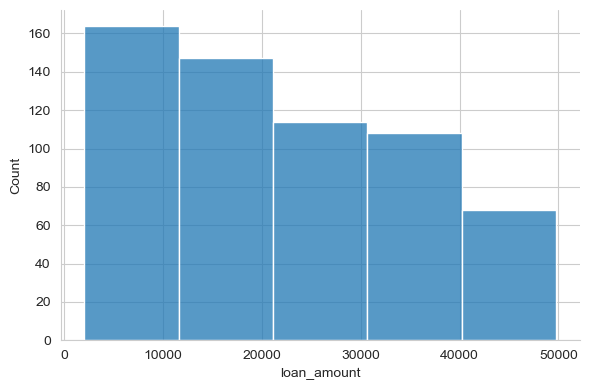

In [42]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                x = 'loan_amount',
                bins = 5, height = 4, aspect = 1.5)
#for ax in g.axes.flat:
#    ax.tick_params('x', labelrotation = 30)

### Review Term Months Data
##### data here is fairly evenly distributed


In [43]:
appData.term_months.value_counts(normalize = True) 

term_months
48    0.227953
36    0.196339
12    0.196339
60    0.196339
24    0.183028
Name: proportion, dtype: float64

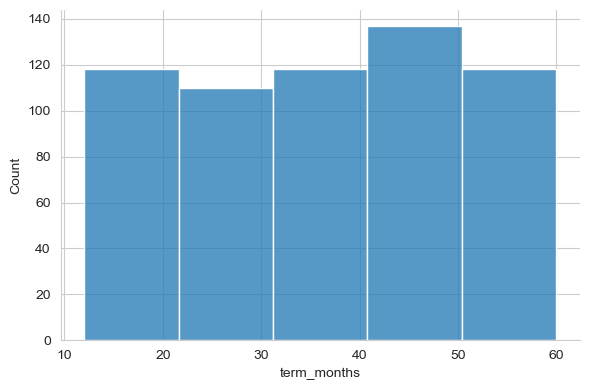

In [44]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                x = 'term_months',
                bins = 5, height = 4, aspect = 1.5)

### Review Interest Rate Data
##### Range from 6-16%
##### Most common rates are between 10-11% (middle of the pack)

In [45]:
appData.interest_rate.describe()

count    601.000000
mean      10.641331
std        2.251153
min        5.860000
25%        8.940000
50%       10.540000
75%       12.330000
max       15.860000
Name: interest_rate, dtype: float64

In [46]:
appData.interest_rate.value_counts(normalize = True) 

interest_rate
10.78    0.006656
10.74    0.006656
10.04    0.006656
9.58     0.006656
11.24    0.006656
8.45     0.006656
10.19    0.004992
10.20    0.004992
9.99     0.004992
10.39    0.004992
13.08    0.004992
14.90    0.004992
13.44    0.004992
9.64     0.004992
7.99     0.004992
8.84     0.004992
11.41    0.004992
11.30    0.004992
10.54    0.004992
9.33     0.004992
12.35    0.004992
10.99    0.004992
10.76    0.004992
12.00    0.004992
11.68    0.004992
11.75    0.004992
9.17     0.004992
10.93    0.004992
9.85     0.004992
10.25    0.004992
7.78     0.004992
10.17    0.004992
7.25     0.004992
11.88    0.004992
12.02    0.004992
10.23    0.004992
10.83    0.004992
12.73    0.004992
9.31     0.003328
9.25     0.003328
8.70     0.003328
8.38     0.003328
10.79    0.003328
11.03    0.003328
14.52    0.003328
9.32     0.003328
7.03     0.003328
14.21    0.003328
11.87    0.003328
9.89     0.003328
15.64    0.003328
11.50    0.003328
10.52    0.003328
6.52     0.003328
10.56    0.003

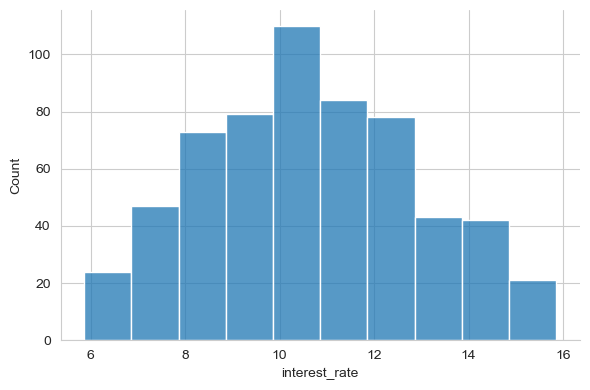

In [47]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                x = 'interest_rate',
                bins = 10, height = 4, aspect = 1.5)

### Review Monthly Payment Data
##### Only a third of the loans have payments around $500 or less, the rest are higher

In [48]:
appData.monthly_payment.value_counts(normalize = True) 

monthly_payment
153.73     0.003328
889.11     0.001664
1698.30    0.001664
1511.02    0.001664
279.03     0.001664
679.91     0.001664
716.45     0.001664
317.63     0.001664
1794.81    0.001664
542.86     0.001664
805.44     0.001664
3457.02    0.001664
825.83     0.001664
900.89     0.001664
1985.96    0.001664
621.06     0.001664
1603.03    0.001664
1266.26    0.001664
156.96     0.001664
538.39     0.001664
1483.37    0.001664
528.25     0.001664
378.57     0.001664
313.66     0.001664
794.04     0.001664
479.22     0.001664
1258.37    0.001664
1840.87    0.001664
737.83     0.001664
425.79     0.001664
1672.36    0.001664
278.53     0.001664
109.04     0.001664
281.40     0.001664
216.95     0.001664
156.23     0.001664
2689.23    0.001664
797.21     0.001664
1766.82    0.001664
2169.53    0.001664
1666.87    0.001664
1363.13    0.001664
1236.48    0.001664
90.56      0.001664
1022.20    0.001664
1120.71    0.001664
444.93     0.001664
1254.61    0.001664
1408.11    0.001664
581.

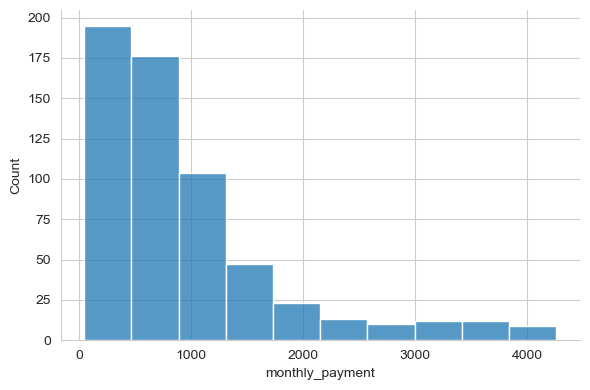

In [49]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                x = 'monthly_payment',
                bins = 10, height = 4, aspect = 1.5)

### Review DTI Ratio Data
##### largest group between 25-50%
##### then 50-75% and 25-50%
##### many of the existing loans had borrowers with a high DTI ratio

In [50]:
appData.dti_ratio.value_counts(normalize = True) 
# LOTS OF VALUES

dti_ratio
64.8     0.008319
52.7     0.008319
56.2     0.006656
37.6     0.006656
45.4     0.006656
69.4     0.006656
26.5     0.006656
32.2     0.006656
40.0     0.006656
30.1     0.006656
54.1     0.006656
56.6     0.006656
36.3     0.006656
32.4     0.006656
38.0     0.006656
32.0     0.006656
10.5     0.004992
12.6     0.004992
45.1     0.004992
43.4     0.004992
55.4     0.004992
38.7     0.004992
31.5     0.004992
51.2     0.004992
38.1     0.004992
59.0     0.004992
49.0     0.004992
48.2     0.004992
32.6     0.004992
47.1     0.004992
49.3     0.004992
51.9     0.004992
50.9     0.004992
49.5     0.004992
17.6     0.004992
23.8     0.004992
54.0     0.004992
29.5     0.004992
39.1     0.004992
29.9     0.004992
36.2     0.004992
47.5     0.004992
70.5     0.004992
29.3     0.004992
57.8     0.003328
70.1     0.003328
52.3     0.003328
60.2     0.003328
36.4     0.003328
44.0     0.003328
59.5     0.003328
57.1     0.003328
36.8     0.003328
67.8     0.003328
18.6     0.003328


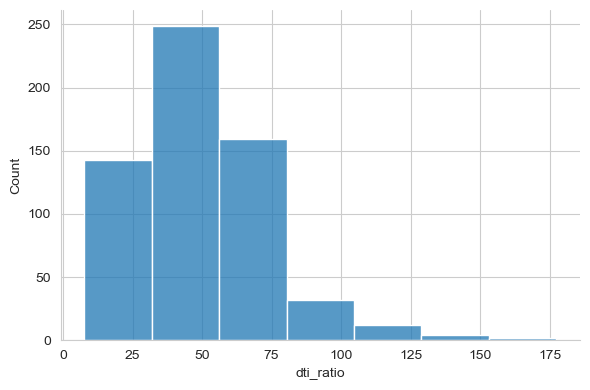

In [51]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                x = 'dti_ratio',
                bins = 7, height = 4, aspect = 1.5)

### Review Loan Status 
##### 40% of data are current
##### 24% of data are defaulted
##### 19% of data are paid off
##### 17% of data are late

In [52]:
appData.loan_status.value_counts(normalize = True) 

loan_status
Current     0.397671
Default     0.242928
Paid Off    0.188020
Late        0.171381
Name: proportion, dtype: float64

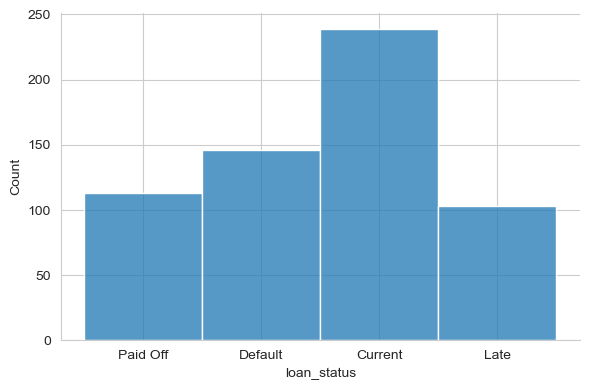

In [53]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                x = 'loan_status',
                bins = 4, height = 4, aspect = 1.5)

### Review Days Delinquent Data
##### 64% of borrowers 0 days delinquent
##### 8% @ 15 days delinquent
##### 4% @ 30 days delinquent
##### rest of days values <1%

In [54]:
appData.days_delinquent.value_counts(normalize = True) 

days_delinquent
0      0.637271
15     0.078203
30     0.041597
78     0.006656
58     0.006656
105    0.004992
63     0.004992
108    0.004992
168    0.004992
32     0.004992
38     0.004992
42     0.004992
102    0.004992
79     0.003328
61     0.003328
127    0.003328
178    0.003328
120    0.003328
161    0.003328
115    0.003328
51     0.003328
134    0.003328
55     0.003328
109    0.003328
151    0.003328
49     0.003328
65     0.003328
177    0.003328
75     0.003328
84     0.003328
112    0.003328
129    0.003328
165    0.003328
113    0.003328
128    0.003328
107    0.003328
170    0.003328
39     0.003328
101    0.003328
116    0.003328
34     0.003328
80     0.003328
155    0.003328
45     0.003328
117    0.003328
44     0.003328
43     0.001664
166    0.001664
153    0.001664
141    0.001664
176    0.001664
98     0.001664
135    0.001664
154    0.001664
94     0.001664
46     0.001664
33     0.001664
144    0.001664
147    0.001664
152    0.001664
103    0.001664
125    0

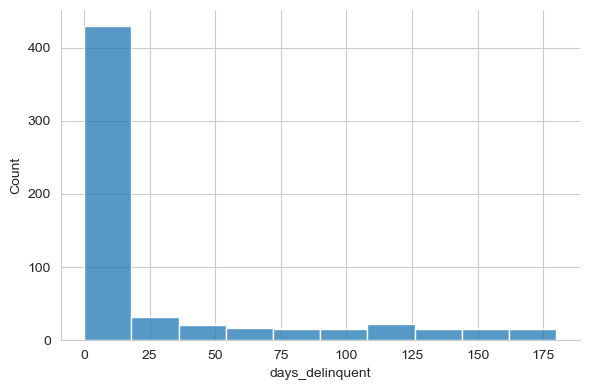

In [55]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                x = 'days_delinquent',
                bins = 10, height = 4, aspect = 1.5)

### Review Defaulted Data
##### 76% of borrowers did not default
##### 24% of borrowers defaulted

In [56]:
appData.defaulted.value_counts(normalize = True) 

defaulted
0    0.757072
1    0.242928
Name: proportion, dtype: float64

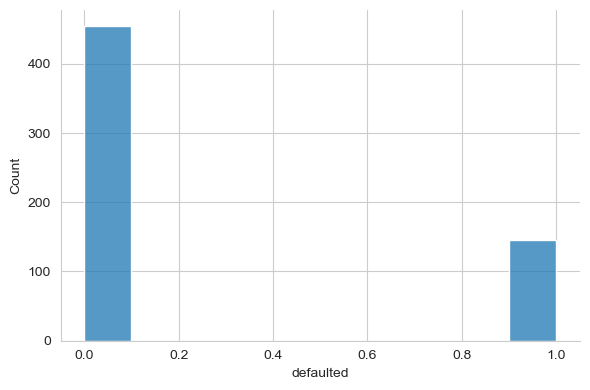

In [57]:
# Assess data distribution
g = sns.displot(kind = 'hist', data = appData,
                x = 'defaulted',
                bins = 10, height = 4, aspect = 1.5)

# Join tables

In [58]:
#profileData = profileData.set_index('borrower_id')
profileData = profileData.reset_index()

In [59]:
joinedData = profileData.merge(right = appData, on = 'borrower_id', suffixes = ('_1', '_2'),
                             how = 'left')

In [60]:
joinedData.head()

,index,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,...,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted
0,0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,...,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0
1,0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,...,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1
2,1,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,...,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0
3,2,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,...,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,34,1
4,3,BRW-0004,43,TX,High School,Full-Time,19,35036,701,Mortgage,...,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,0,0


In [61]:
# save progress
joinedData.to_pickle('joinedData.pkl')